# Disaster Impact Classification Using Artificial Neural Networks: An Urban Resilience Perspective

## Project Overview

This project aims to classify disaster events into low-impact and high-impact categories using disaster-related characteristics and an Artificial Neural Network, with a focus on their implications for urban safety and resilience.

## Objective

The main objective of this project is to classify disaster events into low-impact and high-impact categories and evaluate the performance of an Artificial Neural Network (ANN).

The project also explores the potential application of deep learning in disaster management and urban resilience.

A Logistic Regression model is used as a baseline for comparison.

## Dataset Description

The dataset used in this project is the EM-DAT disaster database, which contains information on disaster events, their characteristics, and their human impacts.

## 1. Import Libraries

In [58]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns

from keras_visualizer import visualizer
from sklearn.model_selection import train_test_split 
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, 
                             f1_score, confusion_matrix, classification_report)

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

## 2. Load Dataset

In [5]:
df = pd.read_excel("public_emdat_2026-10-05.xlsx")

## 3. Initial Data Inspection

In [17]:
print("Dataset Shape:", df.shape, "Dataset Dimension:", df.ndim,"Dataset Size:", df.size)

display(df.head())

df.info()

Dataset Shape: (17075, 47) Dataset Dimension: 2 Dataset Size: 802525


,DisNo.,Historic,Classification Key,Disaster Group,Disaster Subgroup,Disaster Type,Disaster Subtype,External IDs,Event Name,ISO,...,"Reconstruction Costs, Adjusted ('000 US$)",Insured Damage ('000 US$),"Insured Damage, Adjusted ('000 US$)",Total Damage ('000 US$),"Total Damage, Adjusted ('000 US$)",CPI,Admin Units,GADM Admin Units,Entry Date,Last Update
0,2025-0303-ECU,No,nat-geo-ear-gro,Natural,Geophysical,Earthquake,Ground movement,NaN,NaN,ECU,...,NaN,NaN,NaN,NaN,NaN,100.0,NaN,NaN,2025-04-28,2026-05-15
1,2026-0153-KEN,No,nat-hyd-flo-flo,Natural,Hydrological,Flood,Flood (General),NaN,NaN,KEN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2026-03-09,2026-05-15
2,2025-0750-AFG,No,nat-geo-ear-gro,Natural,Geophysical,Earthquake,Ground movement,GLIDE:EQ-2025-000153,NaN,AFG,...,NaN,NaN,NaN,180000.0,180000.0,100.0,NaN,NaN,2025-09-01,2026-05-15
3,2026-0305-AFG,No,nat-hyd-flo-flo,Natural,Hydrological,Flood,Flood (General),NaN,NaN,AFG,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2026-05-04,2026-05-11
4,2024-0962-AGO,No,nat-bio-epi-bac,Natural,Biological,Epidemic,Bacterial disease,GLIDE:EP-2025-000013,Cholera,AGO,...,NaN,NaN,NaN,NaN,NaN,100.0,NaN,NaN,2025-01-17,2026-05-15


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17075 entries, 0 to 17074
Data columns (total 47 columns):
 #   Column                                     Non-Null Count  Dtype  
---  ------                                     --------------  -----  
 0   DisNo.                                     17075 non-null  object 
 1   Historic                                   17075 non-null  object 
 2   Classification Key                         17075 non-null  object 
 3   Disaster Group                             17075 non-null  object 
 4   Disaster Subgroup                          17075 non-null  object 
 5   Disaster Type                              17075 non-null  object 
 6   Disaster Subtype                           17075 non-null  object 
 7   External IDs                               4408 non-null   object 
 8   Event Name                                 5440 non-null   object 
 9   ISO                                        17075 non-null  object 
 10  Country               

## 4. Missing Value Analysis

In [18]:
missing = df.isnull().sum()

missing_percent = (missing / len(df)) * 100

In [21]:
missing_report = pd.DataFrame({
    "Missing": missing,
    "Missing_%": missing_percent,
})

missing_report

,Missing,Missing_%
DisNo.,0,0.000000
Historic,0,0.000000
Classification Key,0,0.000000
Disaster Group,0,0.000000
Disaster Subgroup,0,0.000000
Disaster Type,0,0.000000
Disaster Subtype,0,0.000000
External IDs,12667,74.184480
Event Name,11635,68.140556
ISO,0,0.000000


In [22]:
missing_report = missing_report.sort_values(
    by='Missing_%',
    ascending=False
)

missing_report

,Missing,Missing_%
"Reconstruction Costs, Adjusted ('000 US$)",17041,99.800878
Reconstruction Costs ('000 US$),17040,99.795022
AID Contribution ('000 US$),16585,97.130307
"Insured Damage, Adjusted ('000 US$)",16353,95.771596
Insured Damage ('000 US$),16350,95.754026
River Basin,15725,92.093704
No. Homeless,15692,91.900439
Longitude,15211,89.083455
Latitude,15211,89.083455
"Total Damage, Adjusted ('000 US$)",13726,80.386530


## 5. Data Cleaning

In [23]:
df_candidate = df.loc[:, missing_percent <= 30].copy()

print("Shape after removing columns with >30% missing:")
print(df_candidate.shape)

Shape after removing columns with >30% missing:
(17075, 26)


In [26]:
print("Remaining columns:")
print(df_candidate.columns.tolist())

Remaining columns:
['DisNo.', 'Historic', 'Classification Key', 'Disaster Group', 'Disaster Subgroup', 'Disaster Type', 'Disaster Subtype', 'ISO', 'Country', 'Subregion', 'Region', 'Location', 'OFDA/BHA Response', 'Appeal', 'Declaration', 'Start Year', 'Start Month', 'Start Day', 'End Year', 'End Month', 'End Day', 'Total Deaths', 'Total Affected', 'CPI', 'Entry Date', 'Last Update']


In [27]:
column_summary = pd.DataFrame({
    'Dtype': df_candidate.dtypes,
    'Unique_Values': df_candidate.nunique()
})

column_summary

,Dtype,Unique_Values
DisNo.,object,17075
Historic,object,1
Classification Key,object,63
Disaster Group,object,2
Disaster Subgroup,object,9
Disaster Type,object,31
Disaster Subtype,object,63
ISO,object,223
Country,object,223
Subregion,object,17


In [28]:
# Remove identifier, constant, and administrative columns
df_candidate = df_candidate.drop(
    columns=['DisNo.', 'Historic', 'Entry Date', 'Last Update']
)

print("Shape after removing non-informative columns:")
print(df_candidate.shape)

Shape after removing non-informative columns:
(17075, 22)


In [29]:
df_candidate.isnull().sum()

Classification Key       0
Disaster Group           0
Disaster Subgroup        0
Disaster Type            0
Disaster Subtype         0
ISO                      0
Country                  0
Subregion                0
Region                   0
Location               857
OFDA/BHA Response        0
Appeal                   0
Declaration              0
Start Year               0
Start Month             74
Start Day             1631
End Year                 0
End Month              173
End Day               1548
Total Deaths          3310
Total Affected        4362
CPI                    306
dtype: int64

In [30]:
# Remove rows with missing Total Deaths
df_candidate = df_candidate.dropna(subset=['Total Deaths']).copy()

print("Shape after removing rows with missing Total Deaths:")
print(df_candidate.shape)

Shape after removing rows with missing Total Deaths:
(13765, 22)


In [31]:
print(df_candidate['Total Deaths'].describe())

count     13765.000000
mean        139.845187
std        2976.740351
min           1.000000
25%          10.000000
50%          16.000000
75%          33.000000
max      222570.000000
Name: Total Deaths, dtype: float64


In [32]:
impact_threshold = df_candidate['Total Deaths'].quantile(0.75)

print("Impact threshold:", impact_threshold)

Impact threshold: 33.0


In [36]:
# Create the Impact column to classify disasters as low-impact or high-impact
df_candidate['Impact'] = (
    df_candidate['Total Deaths'] > impact_threshold
).astype(int)

In [35]:
df_candidate['Impact'].value_counts()

Impact
0    10391
1     3374
Name: count, dtype: int64

In [43]:
df_candidate.columns



Index(['Classification Key', 'Disaster Group', 'Disaster Subgroup',
       'Disaster Type', 'Disaster Subtype', 'ISO', 'Country', 'Subregion',
       'Region', 'Location', 'OFDA/BHA Response', 'Appeal', 'Declaration',
       'Start Year', 'Start Month', 'Start Day', 'End Year', 'End Month',
       'End Day', 'Total Deaths', 'Total Affected', 'CPI', 'Impact'],
      dtype='object')

In [44]:
features = [
    'Disaster Group',
    'Disaster Subgroup',
    'Disaster Type',
    'Disaster Subtype',
    'Country',
    'Subregion',
    'Region',
    'Start Year',
    'Start Month',
    'Start Day',
    'End Year',
    'End Month',
    'End Day',
    'CPI'
]

X = df_candidate[features].copy()
y = df_candidate['Impact'].copy()

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (13765, 14)
y shape: (13765,)


In [45]:
X.head()

,Disaster Group,Disaster Subgroup,Disaster Type,Disaster Subtype,Country,Subregion,Region,Start Year,Start Month,Start Day,End Year,End Month,End Day,CPI
1,Natural,Hydrological,Flood,Flood (General),Kenya,Sub-Saharan Africa,Africa,2026,3.0,6.0,2026,3.0,31.0,NaN
2,Natural,Geophysical,Earthquake,Ground movement,Afghanistan,Southern Asia,Asia,2025,8.0,31.0,2025,8.0,31.0,100.0
3,Natural,Hydrological,Flood,Flood (General),Afghanistan,Southern Asia,Asia,2026,4.0,24.0,2026,5.0,1.0,NaN
4,Natural,Biological,Epidemic,Bacterial disease,Angola,Sub-Saharan Africa,Africa,2025,1.0,7.0,2025,10.0,NaN,100.0
6,Natural,Meteorological,Storm,Severe weather,Syrian Arab Republic,Western Asia,Asia,2026,3.0,14.0,2026,3.0,18.0,NaN


In [46]:
X.isnull().sum()

Disaster Group         0
Disaster Subgroup      0
Disaster Type          0
Disaster Subtype       0
Country                0
Subregion              0
Region                 0
Start Year             0
Start Month           23
Start Day            884
End Year               0
End Month             24
End Day              816
CPI                  268
dtype: int64

In [47]:
X[['Start Month', 'Start Day', 'End Month', 'End Day', 'CPI']].dtypes

Start Month    float64
Start Day      float64
End Month      float64
End Day        float64
CPI            float64
dtype: object

In [48]:
# Fill missing values with the median of each numerical feature
numeric_features = ['Start Month', 'Start Day', 'End Month', 'End Day', 'CPI']

for column in numeric_features:
    X[column] = X[column].fillna(X[column].median())

In [49]:
X.isnull().sum()

Disaster Group       0
Disaster Subgroup    0
Disaster Type        0
Disaster Subtype     0
Country              0
Subregion            0
Region               0
Start Year           0
Start Month          0
Start Day            0
End Year             0
End Month            0
End Day              0
CPI                  0
dtype: int64

In [ ]:
# X['Start Month'] = X['Start Month'].fillna(X['Start Month'].median())
# X['Start Day'] = X['Start Day'].fillna(X['Start Day'].median())
# X['End Month'] = X['End Month'].fillna(X['End Month'].median())
# X['End Day'] = X['End Day'].fillna(X['End Day'].median())
# X['CPI'] = X['CPI'].fillna(X['CPI'].median())

## 6. Train-Test Split

In [50]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (11012, 14)
X_test: (2753, 14)
y_train: (11012,)
y_test: (2753,)


## 7. Encode Categorical Features

In [53]:
categorical_features = [
    'Disaster Group',
    'Disaster Subgroup',
    'Disaster Type',
    'Disaster Subtype',
    'Country',
    'Subregion',
    'Region'
]

X_train = pd.get_dummies(
    X_train,
    columns=categorical_features,
    dtype=int
)

X_test = pd.get_dummies(
    X_test,
    columns=categorical_features,
    dtype=int
)

X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

In [54]:
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

X_train shape: (11012, 335)
X_test shape: (2753, 335)


## 8. Feature Scaling

In [55]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("X_train_scaled shape:", X_train_scaled.shape)
print("X_test_scaled shape:", X_test_scaled.shape)

X_train_scaled shape: (11012, 335)
X_test_scaled shape: (2753, 335)


In [56]:
print("X_train_scaled shape:", X_train_scaled.shape)
print("X_test_scaled shape:", X_test_scaled.shape)

print("Missing values in X_train:", np.isnan(X_train_scaled).sum())
print("Missing values in X_test:", np.isnan(X_test_scaled).sum())

X_train_scaled shape: (11012, 335)
X_test_scaled shape: (2753, 335)
Missing values in X_train: 0
Missing values in X_test: 0


## 9. Build Artificial Neural Network

In [57]:
model = Sequential([
    Dense(32, activation='relu', input_shape=(X_train_scaled.shape[1],)),
    Dense(16, activation='relu'),
    Dense(1, activation='sigmoid')
])

model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense (Dense)               (None, 32)                10752     
                                                                 
 dense_1 (Dense)             (None, 16)                528       
                                                                 
 dense_2 (Dense)             (None, 1)                 17        
                                                                 
Total params: 11,297
Trainable params: 11,297
Non-trainable params: 0
_________________________________________________________________


In [59]:
visualizer(
    model,
    file_name='ann_architecture',
    file_format='png'
)

## 10. Compile the ANN Model

In [60]:
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

## 11. Train the ANN Model

In [61]:
history = model.fit(
    X_train_scaled,
    y_train,
    epochs=20,
    batch_size=32,
    validation_split=0.2,
    verbose=1
)

Epoch 1/20
276/276 [==============================] - 2s 3ms/step - loss: 0.5551 - accuracy: 0.7305 - val_loss: 0.5429 - val_accuracy: 0.7517
Epoch 2/20
276/276 [==============================] - 1s 2ms/step - loss: 0.4839 - accuracy: 0.7759 - val_loss: 0.5382 - val_accuracy: 0.7626
Epoch 3/20
276/276 [==============================] - 1s 2ms/step - loss: 0.4654 - accuracy: 0.7848 - val_loss: 0.5353 - val_accuracy: 0.7626
Epoch 4/20
276/276 [==============================] - 1s 2ms/step - loss: 0.4542 - accuracy: 0.7907 - val_loss: 0.5415 - val_accuracy: 0.7603
Epoch 5/20
276/276 [==============================] - 1s 3ms/step - loss: 0.4460 - accuracy: 0.7910 - val_loss: 0.5468 - val_accuracy: 0.7581
Epoch 6/20
276/276 [==============================] - 1s 2ms/step - loss: 0.4385 - accuracy: 0.7940 - val_loss: 0.5457 - val_accuracy: 0.7590
Epoch 7/20
276/276 [==============================] - 1s 2ms/step - loss: 0.4309 - accuracy: 0.7998 - val_loss: 0.5533 - val_accuracy: 0.7549
Epoch 

## 12. Evaluate the ANN Model

In [62]:
test_loss, test_accuracy = model.evaluate(
    X_test_scaled,
    y_test,
    verbose=0
)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

Test Loss: 0.616051197052002
Test Accuracy: 0.7544496655464172


## 13. Classification Metrics

In [63]:
y_pred_prob = model.predict(X_test_scaled)
y_pred = (y_pred_prob >= 0.5).astype(int).ravel()

print(classification_report(y_test, y_pred))

87/87 [==============================] - 0s 2ms/step
              precision    recall  f1-score   support

           0       0.80      0.89      0.85      2078
           1       0.50      0.33      0.40       675

    accuracy                           0.75      2753
   macro avg       0.65      0.61      0.62      2753
weighted avg       0.73      0.75      0.74      2753



## 14. Confusion Matrix

In [64]:
cm = confusion_matrix(y_test, y_pred)

print(cm)

[[1856  222]
 [ 454  221]]


<!-- High Impact واقعی = 454 + 221 = 675

مدل پیدا کرده = 221

221 / 675 ≈ 33% -->

## 15. Confusion Matrix Visualization

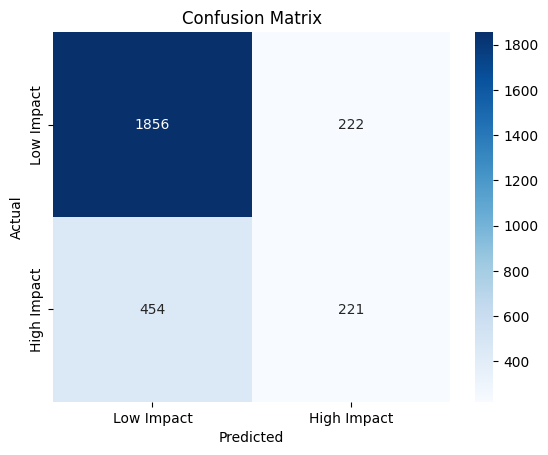

In [65]:
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Low Impact', 'High Impact'],
    yticklabels=['Low Impact', 'High Impact']
)

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

## 16. Logistic Regression Baseline

In [66]:
baseline_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

baseline_model.fit(X_train_scaled, y_train)

LogisticRegression(max_iter=1000, random_state=42)

In [67]:
baseline_pred = baseline_model.predict(X_test_scaled)

print(classification_report(y_test, baseline_pred))

              precision    recall  f1-score   support

           0       0.79      0.95      0.86      2078
           1       0.56      0.21      0.30       675

    accuracy                           0.77      2753
   macro avg       0.67      0.58      0.58      2753
weighted avg       0.73      0.77      0.72      2753



## 17. Model Comparison

In [68]:
comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "ANN"],
    "Accuracy": [0.77, 0.75],
    "Precision": [0.56, 0.50],
    "Recall": [0.21, 0.33],
    "F1 Score": [0.30, 0.40]
})

comparison

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.77,0.56,0.21,0.3
1,ANN,0.75,0.50,0.33,0.4


## 18. Conclusion

In this project, Logistic Regression and an Artificial Neural Network (ANN) were used to classify high-impact disaster events based on selected disaster-related features.

The Logistic Regression model achieved a slightly higher accuracy (0.77), while the ANN achieved a higher recall (0.33) and F1-score (0.40) for the high-impact class. This indicates that the ANN was better at identifying high-impact disaster events, although its overall accuracy was slightly lower.

Overall, the results show that both models can be used for disaster impact classification, with ANN providing a better balance for identifying high-impact events. However, the ANN still missed many high-impact disaster events, indicating that further improvements are needed.

From an urban resilience perspective, this approach could help support disaster prioritization and preparedness by identifying events that may require greater attention from emergency management authorities.